# Payment Performance

## Load data

In [44]:
import pandas as pd

In [45]:
import matplotlib as plt

In [46]:
url = 'https://raw.githubusercontent.com/gitleolopes/python_projects/refs/heads/transactions/payment_performance/data/transactions.csv'

In [47]:
transactions = pd.read_csv(url)
transactions.head()

,transaction_id,merchant_id,transaction_at,amount_cad,transaction_status,channel,payment_method,card_country,external_reference,currency
0,T0000001,M00499,2025-07-04 17:02:35,64.13,Approved,E-commerce,Credit,CA,REF0000001,CAD
1,T0000002,M00069,2025-10-24 01:39:18,389.91,Approved,POS,Credit,CA,REF0000002,CAD
2,T0000003,M00333,2025-06-25 07:50:14,19.37,Approved,POS,Credit,CA,REF0000003,CAD
3,T0000004,M00243,2025-03-12 15:25:47,75.72,Approved,E-commerce,Credit,CA,REF0000004,CAD
4,T0000005,M00820,2026-04-30 05:30:50,75.91,Declined,Mobile,Debit,CA,REF0000005,CAD


## Data Profiling

In [48]:
transactions.shape

(100000, 10)

In [49]:
transactions.columns

Index(['transaction_id', 'merchant_id', 'transaction_at', 'amount_cad',
       'transaction_status', 'channel', 'payment_method', 'card_country',
       'external_reference', 'currency'],
      dtype='object')

In [50]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   transaction_id      100000 non-null  object 
 1   merchant_id         100000 non-null  object 
 2   transaction_at      100000 non-null  object 
 3   amount_cad          100000 non-null  float64
 4   transaction_status  100000 non-null  object 
 5   channel             100000 non-null  object 
 6   payment_method      100000 non-null  object 
 7   card_country        99498 non-null   object 
 8   external_reference  100000 non-null  object 
 9   currency            100000 non-null  object 
dtypes: float64(1), object(9)
memory usage: 7.6+ MB


## Data Types Standardization

In [51]:
transactions['transaction_at'] = pd.to_datetime(transactions['transaction_at'])

In [52]:
transactions.dtypes

,0
transaction_id,object
merchant_id,object
transaction_at,datetime64[ns]
amount_cad,float64
transaction_status,object
channel,object
payment_method,object
card_country,object
external_reference,object
currency,object


## Data Quality

In [53]:
transactions.isnull().sum()

,0
transaction_id,0
merchant_id,0
transaction_at,0
amount_cad,0
transaction_status,0
channel,0
payment_method,0
card_country,502
external_reference,0
currency,0


In [54]:
transactions.transaction_id.duplicated().sum()

np.int64(0)

In [55]:
transactions.transaction_id.nunique()

100000

In [56]:
transactions.channel.unique()

array(['E-commerce', 'POS', 'Mobile'], dtype=object)

In [57]:
transactions.transaction_status.unique()

array(['Approved', 'Declined'], dtype=object)

In [58]:
transactions.transaction_status.value_counts()

,count
transaction_status,
Approved,84233
Declined,15767


In [59]:
transactions.query('amount_cad <= 0')

,transaction_id,merchant_id,transaction_at,amount_cad,transaction_status,channel,payment_method,card_country,external_reference,currency


## Data Transformation

In [60]:
transactions['transaction_month'] = transactions['transaction_at'].dt.to_period('M')

In [61]:
transactions['is_approved'] = transactions['transaction_status'].eq('Approved')

In [62]:
transactions['approved_amount'] = transactions['amount_cad'].where(transactions['is_approved'], 0)

In [63]:
transactions.head()

,transaction_id,merchant_id,transaction_at,amount_cad,transaction_status,channel,payment_method,card_country,external_reference,currency,transaction_month,is_approved,approved_amount
0,T0000001,M00499,2025-07-04 17:02:35,64.13,Approved,E-commerce,Credit,CA,REF0000001,CAD,2025-07,True,64.13
1,T0000002,M00069,2025-10-24 01:39:18,389.91,Approved,POS,Credit,CA,REF0000002,CAD,2025-10,True,389.91
2,T0000003,M00333,2025-06-25 07:50:14,19.37,Approved,POS,Credit,CA,REF0000003,CAD,2025-06,True,19.37
3,T0000004,M00243,2025-03-12 15:25:47,75.72,Approved,E-commerce,Credit,CA,REF0000004,CAD,2025-03,True,75.72
4,T0000005,M00820,2026-04-30 05:30:50,75.91,Declined,Mobile,Debit,CA,REF0000005,CAD,2026-04,False,0.00


## Analysis

### Approval rate

**Why are we analyzing this?**

This analysis aims to establish a baseline for payment performance by measuring the total number of transaction attempts, approved transactions, and overall approval rate.

Understanding the baseline allows us to evaluate merchant-level performance and identify segments that may require further investigation.

In [64]:
attempts = transactions.transaction_id.count()
attempts

np.int64(100000)

In [65]:
approved_attempts = transactions.is_approved.sum()
approved_attempts

np.int64(84233)

In [66]:
approval_rate = (approved_attempts/attempts)*100
approval_rate

np.float64(84.233)

**What did we find?**

The dataset contains 100,000 transaction attempts, with an overall approval rate of approximately 84.23%.

This result provides a baseline for evaluating merchant performance and identifying potential areas for improvement.

**What should we do next?**

Compare approval rates across merchants, payment channels, and time periods to identify where declines are concentrated.

### Merchant KPI table

**Why are we analyzing this?**

This analysis aims to identify merchants with below-average approval rates and determine which merchants should be prioritized for further investigation.

In [67]:
transaction_by_merchant = transactions.groupby('merchant_id').agg(attempts = ('transaction_id', 'count'),
                                        approved_attempts = ('is_approved', 'sum'),
                                        attempted_amount = ('amount_cad', 'sum'),
                                        approved_amount = ('approved_amount', 'sum')).reset_index()

In [68]:
transaction_by_merchant['approval_rate'] = (transaction_by_merchant['approved_attempts']/transaction_by_merchant['attempts'])*100
transaction_by_merchant.sort_values('approval_rate', ascending = False)

,merchant_id,attempts,approved_attempts,attempted_amount,approved_amount,approval_rate
222,M00300,15,15,832.57,832.57,100.000000
438,M00592,15,15,842.32,842.32,100.000000
212,M00286,4,4,180.00,180.00,100.000000
445,M00601,40,39,2455.13,2439.09,97.500000
439,M00594,40,39,1608.61,1606.14,97.500000
...,...,...,...,...,...,...
289,M00389,19,12,1008.56,460.36,63.157895
717,M00964,35,21,1603.23,847.93,60.000000
730,M00979,251,150,14807.90,8240.21,59.760956
739,M00999,293,172,14218.07,7298.03,58.703072


**What did we find?**

Merchants M00979, M00999 and M00489 have an approval rate less than 60%, substantially below the overall average of 84.23%.

This indicates a potential performance issue, although further analysis is needed to determine the reasons for the difference.

**What should we do next?**

Investigate decline reasons, payment channels, and transaction patterns for these merchants.

### Transactions by Channel

**Why are we analyzing this?**

Determine whether approval outcomes differ materially by channel, accounting for transaction volumes.

In [69]:
transaction_by_channel = transactions.groupby('channel').agg(attempts = ('transaction_id', 'count'),
                                    approved_attempts = ('is_approved', 'sum'),
                                    attempted_amount = ('amount_cad', 'sum'),
                                    approved_amount = ('approved_amount', 'sum')).reset_index()

In [70]:
transaction_by_channel['approval_rate'] = (transaction_by_channel['approved_attempts']/transaction_by_channel['attempts'])*100

In [71]:
transaction_by_channel.sort_values('approval_rate', ascending = False)

,channel,attempts,approved_attempts,attempted_amount,approved_amount,approval_rate
2,POS,42110,37053,2917638.07,2565131.65,87.990976
1,Mobile,12027,10299,821151.40,700925.22,85.632327
0,E-commerce,45863,36881,3186411.96,2554506.14,80.415586


<Axes: ylabel='channel'>

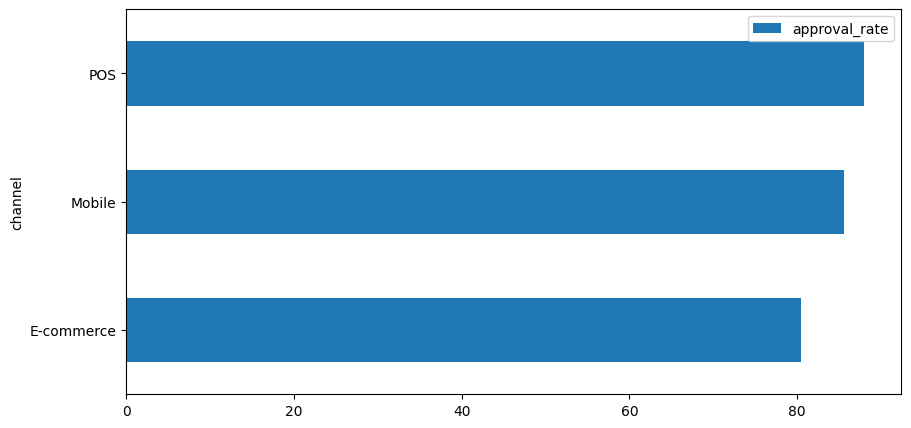

In [72]:
transaction_by_channel.sort_values('approval_rate', ascending = True).plot(kind = 'barh', figsize = (10,5), x = 'channel', y = 'approval_rate')

**What did we find?**

The outputs show E-commerce: 45,863 attempts, 80.42% approved, 8,982 declines; POS: 42,110 attempts, 87.99% approved; Mobile: 12,027 attempts, 85.63% approved. E-commerce made up 57.0% of all declines and had an approval rate about 7.58 percentage points below POS.

**What should we do next?**

Segment E-commerce by merchant and payment method.

### Monthly performance

**Why are we analyzing this?**

Analyse the approval rate over time.

In [73]:
transaction_by_month = transactions.groupby('transaction_month').agg(attempts = ('transaction_id', 'count'),
                                              attempts_approved = ('is_approved', 'sum')).reset_index()

In [74]:
transaction_by_month['approval_rate'] = (transaction_by_month['attempts_approved']/transaction_by_month['attempts'])*100
transaction_by_month

,transaction_month,attempts,attempts_approved,approval_rate
0,2025-01,35,30,85.714286
1,2025-02,356,303,85.112360
2,2025-03,742,637,85.849057
3,2025-04,1192,996,83.557047
4,2025-05,1663,1408,84.666266
5,2025-06,2238,1886,84.271671
6,2025-07,2725,2318,85.064220
7,2025-08,2990,2541,84.983278
8,2025-09,3339,2806,84.037137
9,2025-10,4031,3411,84.619201


<Axes: xlabel='transaction_month'>

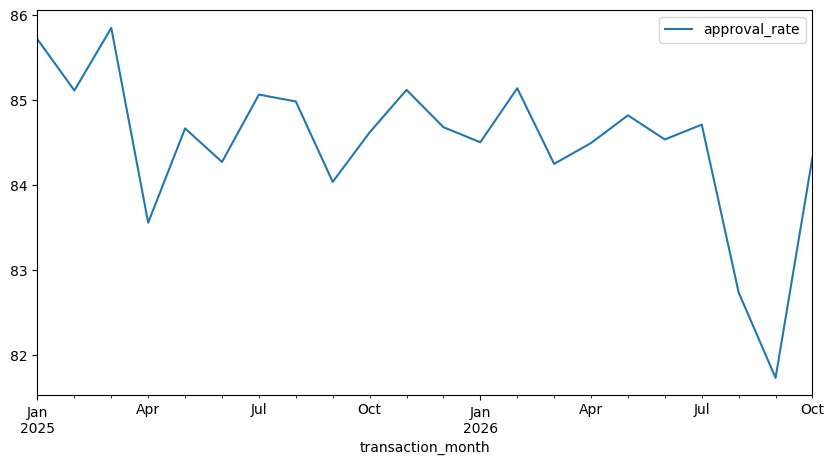

In [75]:
transaction_by_month.plot(kind = 'line', figsize = (10,5), x = 'transaction_month', y = 'approval_rate')

**What did we find?**

The results show 84.71% in July 2026, 82.74% in August, 81.73% in September, and 84.33% in October. A decline occurred, followed by partial recovery.

**What should we do next?**

Compare June–July (baseline) with August–September (investigation period)

### Diagnose the August–September decline

In [76]:
baseline = transactions[(transactions['transaction_month'] == "2026-06") | (transactions['transaction_month'] == "2026-07")]

In [77]:
investigation = transactions[(transactions['transaction_month'] == "2026-08") | (transactions['transaction_month'] == "2026-09")]

In [78]:
transaction_by_merchant_jun_jul = baseline.groupby('merchant_id').agg(attempts_jun_jul = ('transaction_id', 'count'),
                                        approved_attempts_jun_jul = ('is_approved', 'sum')).reset_index()

In [79]:
transaction_by_merchant_aug_sep = investigation.groupby('merchant_id').agg(attempts_aug_sep = ('transaction_id', 'count'),
                                        approved_attempts_aug_sep = ('is_approved', 'sum')).reset_index()

In [80]:
transaction_by_merchant_jun_jul['approval_rate_jun_jul'] = (transaction_by_merchant_jun_jul['approved_attempts_jun_jul']/transaction_by_merchant_jun_jul['attempts_jun_jul'])*100
transaction_by_merchant_jun_jul.sort_values('approval_rate_jun_jul', ascending = False)

,merchant_id,attempts_jun_jul,approved_attempts_jun_jul,approval_rate_jun_jul
726,M00982,4,4,100.000000
722,M00976,5,5,100.000000
691,M00941,5,5,100.000000
28,M00037,5,5,100.000000
22,M00028,6,6,100.000000
...,...,...,...,...
592,M00802,4,2,50.000000
184,M00247,6,3,50.000000
549,M00745,7,3,42.857143
221,M00301,3,1,33.333333


In [81]:
transaction_by_merchant_aug_sep['approval_rate_aug_sep'] = (transaction_by_merchant_aug_sep['approved_attempts_aug_sep']/transaction_by_merchant_aug_sep['attempts_aug_sep'])*100
transaction_by_merchant_aug_sep.sort_values('approval_rate_aug_sep', ascending = False)

,merchant_id,attempts_aug_sep,approved_attempts_aug_sep,approval_rate_aug_sep
734,M00989,5,5,100.000000
551,M00740,9,9,100.000000
20,M00026,6,6,100.000000
19,M00025,10,10,100.000000
22,M00028,7,7,100.000000
...,...,...,...,...
430,M00580,6,2,33.333333
532,M00717,4,1,25.000000
541,M00728,1,0,0.000000
639,M00864,1,0,0.000000


In [82]:
merchant_comparison = transaction_by_merchant_jun_jul.merge(transaction_by_merchant_aug_sep, on = 'merchant_id')

In [83]:
merchant_comparison['rate_change'] = (merchant_comparison['approval_rate_aug_sep'] - merchant_comparison['approval_rate_jun_jul'])

In [84]:
merchant_comparison[(merchant_comparison['attempts_jun_jul'] >= 30) & (merchant_comparison['attempts_aug_sep'] >= 30)].sort_values('rate_change', ascending=True)

,merchant_id,attempts_jun_jul,approved_attempts_jun_jul,approval_rate_jun_jul,attempts_aug_sep,approved_attempts_aug_sep,approval_rate_aug_sep,rate_change
580,M00784,42,38,90.476190,32,22,68.750000,-21.726190
315,M00430,43,41,95.348837,42,31,73.809524,-21.539313
309,M00418,41,37,90.243902,53,38,71.698113,-18.545789
349,M00477,43,39,90.697674,37,27,72.972973,-17.724701
432,M00589,40,35,87.500000,32,23,71.875000,-15.625000
...,...,...,...,...,...,...,...,...
498,M00681,40,31,77.500000,38,34,89.473684,11.973684
601,M00817,38,28,73.684211,39,34,87.179487,13.495277
475,M00650,42,34,80.952381,39,37,94.871795,13.919414
170,M00231,33,23,69.696970,39,33,84.615385,14.918415


**What did we find?**

The overall approval rate declined from approximately 84.63% in June–July 2026 to 82.23% in August–September 2026, representing a decrease of approximately 2.39 percentage points.

Among merchants with at least 30 transaction attempts in each period, M00784 and M00430 experienced the largest observed declines, exceeding 21 percentage points.

**What should we do next?**

Prioritize further investigation into channels and merchants based on both approval rate changes and transaction volume. Additional decline reason and operational data would help determine whether the observed deterioration reflects actionable issues.

## Key findings, recommendations & monitoring

1. Key Findings

Finding 1 — E-commerce has the lowest approval rate

E-commerce recorded an approval rate of 80.42%, compared with 87.99% for POS and 85.63% for Mobile. Despite accounting for approximately 46% of transaction attempts, E-commerce represented around 57% of declined transactions.

Business implication: E-commerce is a priority area for further investigation due to its relatively low approval rate and high transaction volume.

Finding 2 — Approval rates declined in August and September

The overall approval rate decreased from approximately 84.63% in June–July to 82.23% in August–September 2026, a decline of 2.39 percentage points.

Business implication: This deterioration warrants further investigation to determine whether it was driven by specific merchants, payment channels, or changes in transaction composition.

Finding 3 — Some merchants experienced significant performance declines

Among merchants with at least 30 transaction attempts in both periods, M00784 and M00430 experienced approval rate declines exceeding 21 percentage points.

However, their relatively small transaction volumes mean they cannot automatically be considered the main contributors to the overall decline.

Business implication: Merchant performance should be evaluated using both approval rate changes and transaction volumes to identify meaningful business impact.


2. Business Recommendations

Recommendation 1 — Prioritize an E-commerce performance investigation

Analyze approval rates by merchant, payment method, and time period within E-commerce. Identify whether declines are concentrated in specific segments before proposing corrective actions.

Recommendation 2 — Investigate the August–September decline

Compare channel-level and merchant-level performance between the baseline and investigation periods. Prioritize segments showing both meaningful approval rate deterioration and significant transaction volumes.

Recommendation 3 — Expand the analysis with additional operational data

Incorporate decline reason codes and operational incident data, where available, to better understand the potential causes of declined transactions and distinguish technical issues from other types of declines.


3. Monitoring & Success Metrics

To evaluate performance and identify future deterioration, monitor:

Overall approval rate: Track payment approval performance over time.

Approval rate by channel: Identify underperforming payment channels.

Merchant approval rate: Monitor merchants with substantial transaction volumes and declining performance.

Declined transaction volume: Measure the number of unsuccessful attempts and their distribution across segments.